## Генераторы случайных чисел

![img](https://cdn.ablebits.com/_img-blog/random-generator/random-generator.png)

Желаемые свойства ГСЧ:
* моделирует равномерное распределение на [0, 1]
* проходит статистические тесты (какие?)
* высокая скорость работы
* большой период
* может работать на любом вычислительном устройстве
* воспроизводимость (а как же случайность?)
* криптографическая устойчивость (это не противоречит предыдущим требованиям?)

Генератор псевдослучайных чисел - это __алгоритм__ (!!!), который проходит статистические тесты.

### Middle-square algorithm
John von Neumann, 1949

Идея:
1. задаем четырехзначный seed - первое число случайной последовательности
2. возводим в квадрат, получаем 8-ми значное число (при необходимости, дополняем нулями)
3. берем четырехзначное число из середины - это следующий элемент случайной последовательности
4. повторяем 2-3

In [2]:
import numpy as np

def midsquare(val, n=4):
    return int(str(val**2).zfill(2*n)[n//2:-n//2])

seed = 5497
seq = [seed]
for _ in range(100):
    seq.append(midsquare(seq[-1]))
np.array(seq)

array([5497, 2170, 7089, 2539, 4465, 9362, 6470, 8609, 1148, 3179, 1060,
       1236, 5276, 8361, 9063, 1379, 9016, 2882, 3059, 3574, 7734, 8147,
       3736, 9576, 6997, 9580, 7764, 2796, 8176, 8469, 7239, 4031, 2489,
       1951, 8064,  280,  784, 6146, 7733, 7992, 8720,  384, 1474, 1726,
       9790, 8441, 2504, 2700, 2900, 4100, 8100, 6100, 2100, 4100, 8100,
       6100, 2100, 4100, 8100, 6100, 2100, 4100, 8100, 6100, 2100, 4100,
       8100, 6100, 2100, 4100, 8100, 6100, 2100, 4100, 8100, 6100, 2100,
       4100, 8100, 6100, 2100, 4100, 8100, 6100, 2100, 4100, 8100, 6100,
       2100, 4100, 8100, 6100, 2100, 4100, 8100, 6100, 2100, 4100, 8100,
       6100, 2100])

Может быть усложним алгоритм, добавив еще несколько операций?

```
… random numbers should not be
generated with a method chosen at
random. Some theory should be
used.
```
D. Knuth

### Linear congruential generator (LCG)

Linear congruential generator производит последовательность:
$$ z_{i+1} = (az_i + c) \mod m $$

Число $z_0$ называется *seed* и обеспечивает воспроизводимость последовательности “случайных” чисел.

Напишем функцию, которая реализует LCG (на практике чуть сложнее):

In [3]:
def rng(m=2**32, a=1103515245, c=12345):
    rng.current = (a * rng.current + c) % m
    return rng.current / m

# setting the seed
rng.current = 1

Выведем несколько первых элементов последовательности:

In [4]:
[rng() for _ in range(10)]

[0.25693503906950355,
 0.5878706516232342,
 0.15432575810700655,
 0.767266943352297,
 0.9738139626570046,
 0.5858681506942958,
 0.8511155843734741,
 0.6132153405342251,
 0.7473867232911289,
 0.06236015981994569]

Как проверить, что последовательность действительно похожа на выборку из равномерного распределения?

Сделаем выборку побольше

In [5]:
samples = [rng() for _ in range(1000)]

В качестве первого шага построим гистограмму

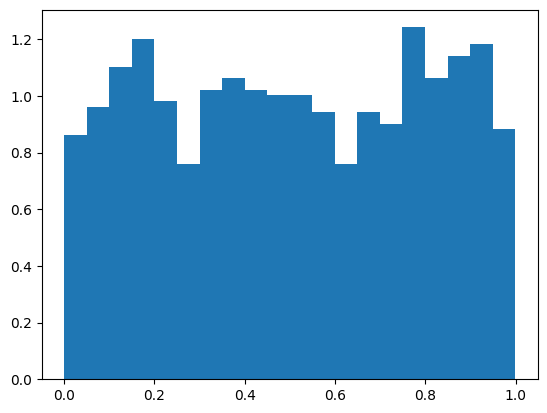

In [14]:
import matplotlib.pyplot as plt

fig = plt.figure()
fig.patch.set_facecolor('xkcd:white')
plt.hist(samples, bins=20, density=True)
plt.show()

На вид гистограммма не противоречит гипотезе о равномерности распределения, но нужны более точные количественные оценки. Их получают с помощью статистических тестов.

###Статистические тесты

Общая идея статистических тестов. Пусть мы хотим проверить гипотезу о том, что выборка Х принадлежит некоторому конкретному (совершенно конкретному) распределению F. Задача состоит в том, чтобы придумать такую статистику (функцию от выборки) T(X), которая в случае истинности нашей гипотезы будет иметь (при $n\to\infty$) наперед известное распределение, например N(0, 1). Посчитаем значение статистики Т=Т(Х) на нашей выборке. Если полученное число Т окажется крайне нетипичным для нормального N(0, 1) распределения, отвергнем гипотезу. Более точно, вычислим $p=P(|\xi|\ge|T|)$ для $\xi\sim N(0,1)$. Это число $p$ имеет специальное название: $p$-value. Если оно маленькое, например, меньше 0.05, то это повод отвергнуть гипотезу.

Далее обсудим конкретные тесты.


### Kolmogorov-Smirnov test

Проверяем гипотезу, что выборка получена из распределения F.
Вычисляем статистику
$$T(X) = \sup_x| F(x) - F_n(x)|,$$
где $F_n(x)$ - эмпирическая функция распределения, построенная по выборке Х объема n.
По сути, Т - это наибольшее расстояние между двумя графиками (см. картинку ниже).

Оказывается, что в случае истинности гипотезы, величина $ \sqrt{n}T$ имеет (в пределе больших n) особое распределение, которое называется [распределением Колмогорова](https://ru.wikipedia.org/wiki/%D0%A0%D0%B0%D1%81%D0%BF%D1%80%D0%B5%D0%B4%D0%B5%D0%BB%D0%B5%D0%BD%D0%B8%D0%B5_%D0%9A%D0%BE%D0%BB%D0%BC%D0%BE%D0%B3%D0%BE%D1%80%D0%BE%D0%B2%D0%B0).

Распределение Колмогорова является табличным, поэтому для любого значения статистики Т мы можем найти $p$-value и увидеть, будет оно маленьким или нет.

![](https://upload.wikimedia.org/wikipedia/commons/thumb/c/cf/KS_Example.png/450px-KS_Example.png)

На практике все делается одной строкой (проверяет гипотезу о принадлежности выбоки равномерному распределению ```stats.uniform.cdf```):

In [6]:
from scipy import stats

stats.kstest(samples, stats.uniform.cdf)

KstestResult(statistic=np.float64(0.026368738710880302), pvalue=np.float64(0.48207388563860043), statistic_location=np.float64(0.7513687387108803), statistic_sign=np.int8(-1))

Как интерпретировать результаты?

statistic=0.02636 - значение статистики (максимальное расстояние между графиками)

pvalue=0.48921 - pvalue для этого значения статистики. Видим, что pvalue > 0.05, так что мы решаем НЕ отвергать гипотезу о равномерном распределении.

Для сравнения, проверим гипотезу, что выборка порождена нормальным законом:

In [7]:
stats.kstest(samples, stats.norm.cdf)

KstestResult(statistic=np.float64(0.500866322716208), pvalue=np.float64(1.4724733582412854e-232), statistic_location=np.float64(0.00969158555381), statistic_sign=np.int8(-1))

Здесь pvalue крайне маленькое, и мы смело отвергаем гипотезу.

### Chi-squared test (Pearson's chi-squared test)

Один из самых популярных тестов. Снова проверяем гипотезу, что выборка (объема n) пришла из распределения F. Идея в том, чтобы разбить всю область определения случайной величины на К интервалов и в каждом интервале посчитать, сколько элементов выборки попало в данный интервал и сколько мы бы ожидали там увидеть, если бы выборка имела размер n и порождалась распределением F. Составляем статистику
$$\chi^2_{K-1}=\sum\limits_{i=1}^{K}\frac{(E_i-O_i)^2}{E_i}$$

$E_i, O_i$ - ожидаемые (expected) и наблюдаемые (observed) количества элементов выборки в i-ом интервале значений.

Рекомендуется выбирать K таким, чтобы $O_i, E_i \ge 5$.

Если гипотеза верна, то статистика критерия имеет (в пределе больших n) распределение хи-квадрат с К-1 степенью свободы.

Пример применения теста хи-квадрат:

In [8]:
k = 20
f_obs = np.histogram(samples, np.linspace(0, 1, k+1))[0]
f_exp = np.full(k, len(samples) // k)

f_obs, f_exp, stats.chisquare(f_obs, f_exp)

(array([42, 49, 55, 60, 49, 38, 51, 53, 51, 50, 50, 47, 38, 47, 45, 65, 50,
        60, 56, 44]),
 array([50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50,
        50, 50, 50]),
 Power_divergenceResult(statistic=np.float64(18.599999999999998), pvalue=np.float64(0.48275240319942647)))

Вывод - наблюдаемое значение статистики не противоречит гипотезе о равномерном распределении.

Проблема: последовательности ```sorted(samples)``` и ```samples``` неразличимы для KS и Chi2 тестов. Нужны дополнительные тесты.


### Serial test

Идея: разбить последовательность $x_1, x_2, x_3, ..., x_{2n}$ на последовательные серии длины 2: $(x_1, x_2), (x_3, x_4), ..., (x_{2n-1}, x_{2n})$ и посмотреть на каждый элемент как на случайную и независимую точку в 2D пространстве. Далее применить хи-квадрат. Аналогично, можно строить серии длины 3, 4 и т.д.

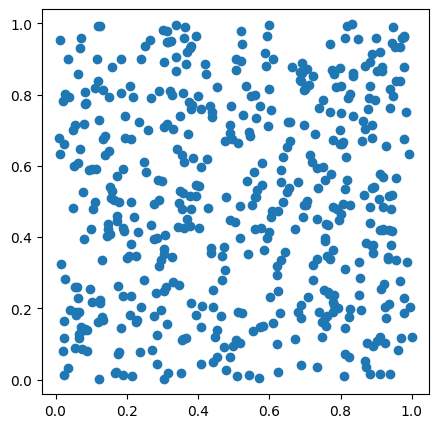

In [15]:
fig = plt.figure(figsize=(5, 5))
fig.patch.set_facecolor('xkcd:white')

plt.scatter(samples[::2], samples[1::2])
plt.axis('equal')
plt.show()

### Задача 1*
Реализовать serial test и применить к выборке samples

In [12]:
import numpy as np
from scipy import stats

def serial_test(samples, m=2, k=10):

    samples = np.asarray(samples)
    n_blocks = len(samples) // m
    blocks = samples[:n_blocks * m].reshape(n_blocks, m)


    edges = np.linspace(0, 1, k + 1)


    codes = np.zeros(n_blocks, dtype=int)
    for j in range(m):
        b = np.digitize(blocks[:, j], edges[1:-1])
        codes = codes * k + b


    f_obs = np.bincount(codes, minlength=k**m)


    f_exp = np.full(k**m, n_blocks / k**m)

    return f_obs, f_exp, stats.chisquare(f_obs, f_exp)

f_obs, f_exp, res = serial_test(samples, m=2, k=10)
print(res)

Power_divergenceResult(statistic=np.float64(117.19999999999999), pvalue=np.float64(0.10232432798233101))


### Permutation test

Снова разобъем последовательность $x_1, x_2, x_3, ..., x_{dn}$ на последовательные серии длины d: $(x_1, ..., x_d), (x_{d+1}, x_{2d+d}), ..., (x_{nd-d}, x_{nd})$. Серия из d элементов может быть упорядочена d! способами и каждый способ упорядочивания равновероятен. Отсюда идея теста - посчитать, сколько раз каждый порядок встречается среди n серий и применить хи-квадрат тест.

### Задача 2*
Реализовать permutation test и применить к выборке samples

In [13]:
import numpy as np
from scipy import stats
from itertools import permutations
from math import factorial

def permutation_test(samples, d=3):

    samples = np.asarray(samples)
    n = len(samples) // d
    blocks = samples[:n * d].reshape(n, d)


    orders = np.argsort(np.argsort(blocks, axis=1), axis=1)


    powers = d ** np.arange(d - 1, -1, -1)
    codes = orders @ powers

    perms = np.array(list(permutations(range(d))))
    perm_codes = perms @ powers
    code_to_idx = {c: i for i, c in enumerate(perm_codes)}

    f_obs = np.zeros(factorial(d), dtype=int)
    for c in codes:
        f_obs[code_to_idx[c]] += 1

    f_exp = np.full(factorial(d), n / factorial(d))

    return f_obs, f_exp, stats.chisquare(f_obs, f_exp)

f_obs, f_exp, res = permutation_test(samples, d=2)
print(res)

f_obs, f_exp, res = permutation_test(samples, d=3)
print(res)

f_obs, f_exp, res = permutation_test(samples, d=4)
print(res)

Power_divergenceResult(statistic=np.float64(0.008), pvalue=np.float64(0.9287300745648026))
Power_divergenceResult(statistic=np.float64(4.855855855855856), pvalue=np.float64(0.4337239950364654))
Power_divergenceResult(statistic=np.float64(17.648), pvalue=np.float64(0.7762927747547669))


Выбор параметров $m$, $a$ и $c$ существенно влияет на качество последовательности. Если параметры выбрать неудачно, это может привести к неожиданным последствиям:

In [16]:
def rng_bad(m=2**31, a=65539, c=0):
    rng_bad.current = (a * rng_bad.current + c) % m
    return rng_bad.current / m
rng_bad.current = 1

random = [rng_bad() for _ in range(30000)]
print("This sequence looks as random:")
random[:10]

This sequence looks as random:


[3.051897510886192e-05,
 0.00018310965970158577,
 0.0008239871822297573,
 0.003295936156064272,
 0.012359732296317816,
 0.04449496837332845,
 0.15573221957311034,
 0.533938602078706,
 0.8020416363142431,
 0.006802399177104235]

Гистограмма распределения похожа на равномерное:

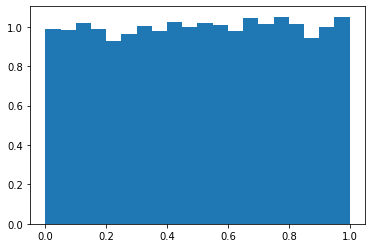

In [ ]:
import matplotlib.pyplot as plt
fig = plt.figure()
fig.patch.set_facecolor('xkcd:white')

plt.hist(random, 20, density=True)
plt.show()

Однако, тест серий показывает, что точки располагаются на гиперплоскостях, что плохо согласуется с представлением о случайности:

<IPython.core.display.Javascript object>


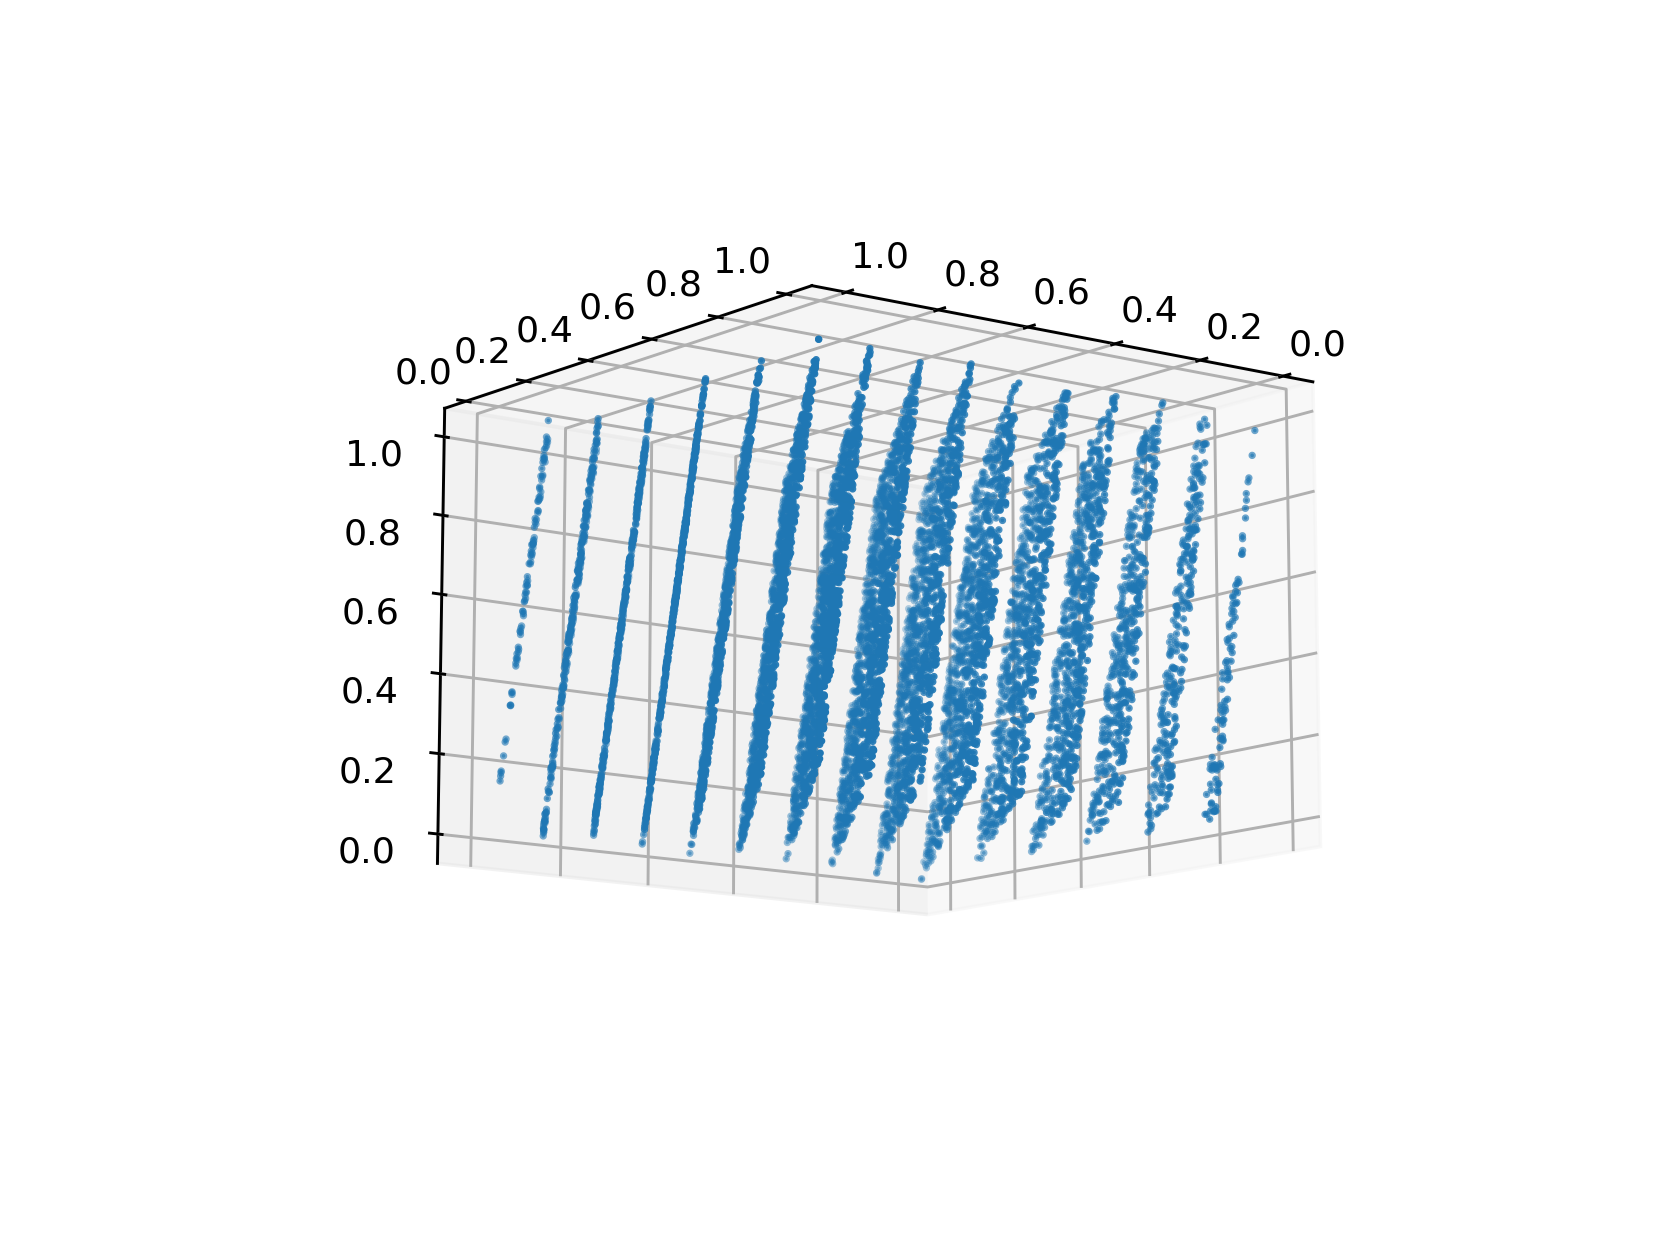

In [ ]:
import matplotlib
%matplotlib notebook
fig = plt.figure()
ax = fig.add_subplot(projection='3d')

ax.scatter(random[::3], random[1::3], random[2::3], s=1)
plt.show()

### Задача 3*

Привести статистический тест, который покажет, что с rng_bad есть проблемы, а с rng - нет.

In [26]:
#Проведём наш трёхмерный serial_test
f_obs, f_exp, res = serial_test(samples, m=3, k=15)
print(res)
f_obs, f_exp, res = serial_test(random, m=3, k=15)
print(res)  # практически ноль

Power_divergenceResult(statistic=np.float64(3447.405405405405), pvalue=np.float64(0.1853143689548067))
Power_divergenceResult(statistic=np.float64(6180.425), pvalue=np.float64(1.3377999257604103e-168))


Больше тестов на случайность - [Diehard tests](https://en.wikipedia.org/wiki/Diehard_tests).

Больше методов генерации равномерной величины [здесь](https://en.wikipedia.org/wiki/List_of_random_number_generators).

Сюжет про динамические системы и переход к хаосу https://www.youtube.com/watch?v=ovJcsL7vyrk&feature=youtu.be

## Генерация выборки из заданного распределения

Допустим, у нас есть генератор случайных числе из отрезка [0, 1] (используйте для этого функцию `np.random.rand()`). Как получить выборку из другого распределения $F$?



### Задача 4
Смоделировать выборку объема 1000 из дискретного распределения на множестве цифр 0, 1, 2, ..., 9 с весами 0.12, 0.3, 0.167, 0.24, 0.31, 0.54, 0.111, 0.02, 0.001, 0.2. По выборке построить гистограмму. Оптимизируйте алгоритм, упорядочив веса.

Эмпирические: [0.044 0.162 0.079 0.104 0.154 0.285 0.069 0.008 0.    0.095]
Теоретические: [0.06  0.149 0.083 0.119 0.154 0.269 0.055 0.01  0.    0.1  ]


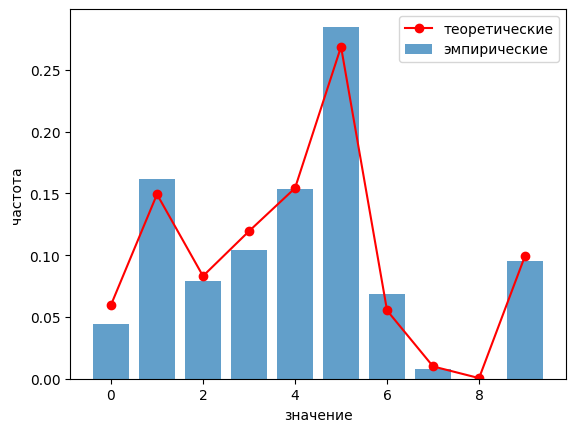

In [28]:
import numpy as np
import matplotlib.pyplot as plt


weights = np.array([0.12, 0.3, 0.167, 0.24, 0.31, 0.54, 0.111, 0.02, 0.001, 0.2])
values  = np.arange(10)
probs   = weights / weights.sum()    # нормировка!

order        = np.argsort(probs)
probs_sorted = probs[order]
values_sorted = values[order]
cdf          = np.cumsum(probs_sorted)

N = 1000
U = np.random.rand(N)
samples = values_sorted[np.searchsorted(cdf, U)]

emp = np.bincount(samples, minlength=10) / N
print("Эмпирические:", np.round(emp, 3))
print("Теоретические:", np.round(probs, 3))

plt.bar(values, emp, alpha=0.7, label="эмпирические")
plt.plot(values, probs, 'ro-', label="теоретические")
plt.legend(); plt.xlabel("значение"); plt.ylabel("частота")
plt.show()


### Inverse transform method

В следующем предложении заключается идея метода *inverse transform*:

Если $\xi$ имеет равномерное распределение в $[0,1]$, тогда $F^{-1}(\xi)$ распределена по закону $F$. (Для каких $F$ это верно?)

### Задача 5
Смоделируйте выборку размера 1000 из распределения $Exp(\lambda)$ с помощью метода Inverse transform. Постройте выборочную гистограмму и точный график плотности распределения.

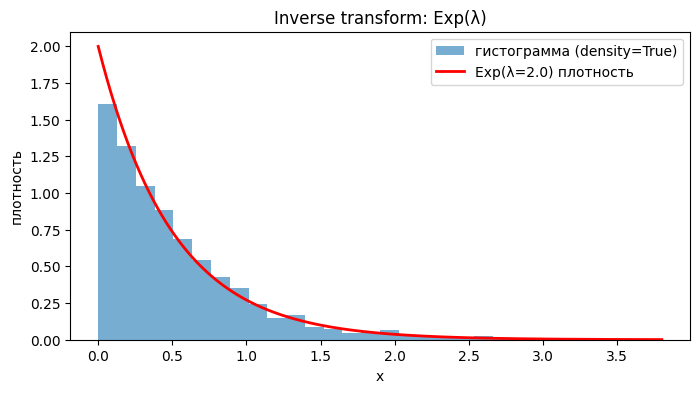

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats


lam = 2.0
N = 1000


rng = np.random.default_rng(0)
xi = rng.random(N)
samples = -np.log(1 - xi) / lam

x_grid = np.linspace(0, samples.max(), 400)

plt.figure(figsize=(8, 4))
plt.hist(samples, bins=30, density=True,
         alpha=0.6, label="гистограмма (density=True)")
plt.plot(x_grid, stats.expon.pdf(x_grid, scale=1/lam),
         'r-', lw=2, label=f"Exp(λ={lam}) плотность")
plt.xlabel("x"); plt.ylabel("плотность")
plt.legend(); plt.title("Inverse transform: Exp(λ)")
plt.show()



### Rejection sampling (Accept-reject method)

Идея метода: сэмплить из распределения, из которого умеем, а затем отбирать точки, которые следуют нужному распределению. Более точно: пусть умеем моделировать выборку из распределения с плотностью $p$, а хотим получить выборку из распределения с плотностью $\pi$. Возьмем случайный $x$ из распределения $p$. Затем возьмем $y$, равномерно распределенный на интервале $[0, p(x)]$. Если точка $(x, y)$ попала под график $\pi$, то примем $x$ за элемент выборки из $\pi$. Если нет - повторяем процедуру для нового $x$. Картинка иллюстрирует идею метода (плотности нормируются так, чтобы одна лежала целиком под другой):
<img src=https://colcarroll.github.io/hamiltonian_monte_carlo_talk/images/bayes_talk.015.png style="width: 50%;"/>


### Задача 6
Обоснуйте (устно), что метод accept-reject действительно производит выборку из нужного распределения. Смоделируйте 1000 точек из распределения с плотностью $e^xcos^2x$ на отрезке $[-\pi/2, \pi/2]$. По выборке постройте график выборочной гистограммы и сравните его с графиком точной функции плотности.

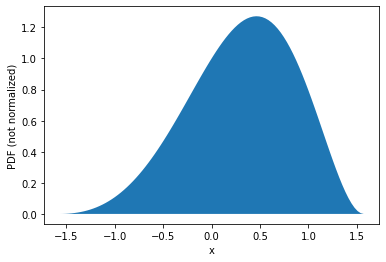

In [ ]:
%matplotlib inline
fig = plt.figure()
fig.patch.set_facecolor('xkcd:white')

x = np.linspace(-np.pi/2, np.pi/2, 100)
density = np.exp(x)*np.cos(x)**2 # not normalized density!
plt.fill_between(x, 0, density)
plt.ylabel('PDF (not normalized)')
plt.xlabel('x')
plt.show()

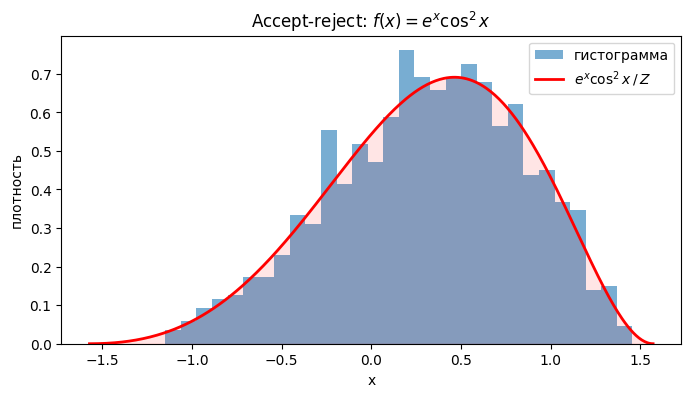

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate

%matplotlib inline


def h(x):
    return np.exp(x) * np.cos(x)**2

a, b = -np.pi/2, np.pi/2
x_star = np.arctan(0.5)
M = h(x_star)


rng = np.random.default_rng(0)
N = 1000
accepted = []
n_total = 0
while len(accepted) < N:
    batch = N - len(accepted)
    Y = rng.uniform(a, b, size=batch)
    U = rng.random(batch)
    keep = U <= h(Y) / M
    accepted.extend(Y[keep])
    n_total += batch
accepted = np.array(accepted[:N])

Z, _ = integrate.quad(h, a, b)

def pdf(x):
    return h(x) / Z

fig, ax = plt.subplots(figsize=(8, 4))
x_grid = np.linspace(a, b, 400)

ax.hist(accepted, bins=30, density=True, alpha=0.6, label="гистограмма")
ax.plot(x_grid, pdf(x_grid), 'r-', lw=2, label=r"$e^x\cos^2 x \,/\, Z$")
ax.fill_between(x_grid, 0, h(x_grid)/Z, color='red', alpha=0.1)

ax.set_xlabel("x"); ax.set_ylabel("плотность")
ax.legend(); ax.set_title("Accept-reject: $f(x)= e^x\\cos^2 x$")
plt.show()

##  Coordinate transformation method

Метод аccept-reject в ряде случаев может оказываться неэффективным и требовать слишком много пробных точек. Альтернатива -  попробовать найти преобразование координат, которое переводит простую область (из которой легко сэмплить, например, едининчный квадрат) в требуемую, но при этом сохраняет соотношение площадей (зачем?).

### Задача 7
Смоделировать и изобразить выборку из 500 точек равномерно распределенных внутри данного треугольника без использования метода отбора.

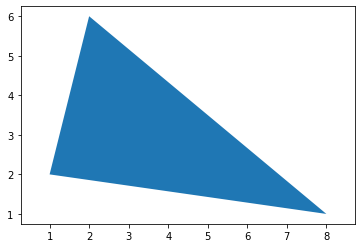

In [ ]:
%matplotlib inline
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection

fig = plt.figure()
fig.patch.set_facecolor('xkcd:white')

polygon = Polygon(np.array([[1, 2], [2, 6], [8, 1]]), True)
plt.gca().add_collection(PatchCollection([polygon]))
plt.axis('equal')
plt.show()

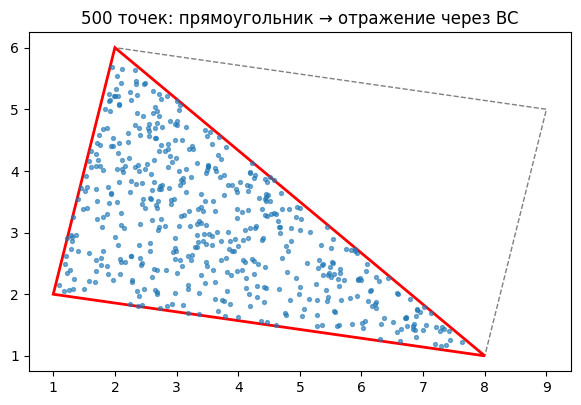

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection

%matplotlib inline
# достроим до параллелограма, сгенерируем точку в нём и отразим, если она будет выше диагонали
A = np.array([1.0, 2.0])
B = np.array([2.0, 6.0])
C = np.array([8.0, 1.0])
D = B + C - A

N = 500
rng = np.random.default_rng(0)


s = rng.random(N)
t = rng.random(N)


mask = (s + t) > 1
s_new = np.where(mask, 1 - t, s)
t_new = np.where(mask, 1 - s, t)

points = A + np.outer(s_new, B - A) + np.outer(t_new, C - A)


fig, ax = plt.subplots(figsize=(7, 5))


para = Polygon(np.array([A, B, D, C]), closed=True,
               fill=False, edgecolor='gray', ls='--', lw=1)
ax.add_patch(para)


tri = Polygon(np.array([A, B, C]), closed=True,
              fill=False, edgecolor='red', lw=2)
ax.add_patch(tri)

ax.scatter(points[:, 0], points[:, 1], s=8, alpha=0.6)
ax.set_aspect('equal')
ax.set_title("500 точек: прямоугольник → отражение через BC")
plt.show()

### Задача 8
Смоделировать без использования метода отбора выборку из 500 точек равномерно распределенных внутри единичного круга. Изобразите полученные точки. Они действительно равномерно заполняют круг?

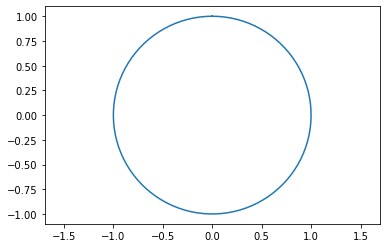

In [ ]:
%matplotlib inline
fig = plt.figure()
fig.patch.set_facecolor('xkcd:white')

t = np.linspace(0, 2 * np.pi, 100)
plt.plot(np.sin(t), np.cos(t))
plt.axis('equal')
plt.show()

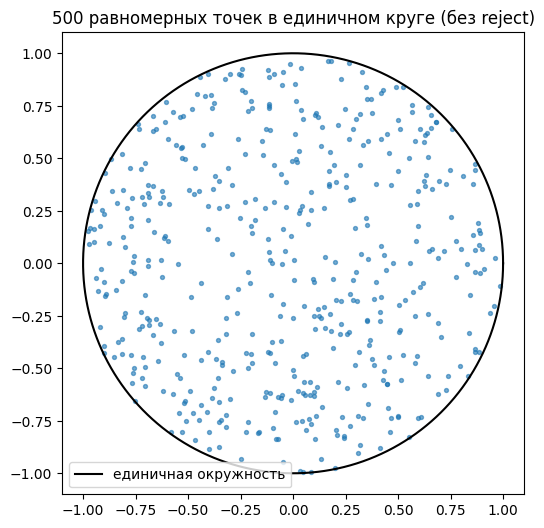

In [38]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

N = 500
rng = np.random.default_rng(0)


xi1 = rng.random(N)
xi2 = rng.random(N)

r = np.sqrt(xi1)            # sqrt, а не xi1
theta = 2 * np.pi * xi2

x = r * np.cos(theta)
y = r * np.sin(theta)


fig, ax = plt.subplots(figsize=(6, 6))
t = np.linspace(0, 2*np.pi, 200)
ax.plot(np.cos(t), np.sin(t), 'k-', lw=1.5, label="единичная окружность")
ax.scatter(x, y, s=8, alpha=0.6)
ax.set_aspect('equal')
ax.set_title("500 равномерных точек в единичном круге (без reject)")
ax.legend()
plt.show()

## Random normal generator

### Задача 9
Докажите (устно), что приведенный ниже алгоритм (Box-Muller algorithm) формирует выборку из независимых N(0,1) случаных величин. Модифицируйте метод, чтобы исключить вызовы тригонометрических функций ```np.sin``` и ```np.cos```. С помощью модифицированного метода смоделируйте выборку объема 1000 из двумерного гауссовского распределения со средним [4, 7] и ковариационной матрицей [[20,  -4],
       [ -4, 40]]. Постройте 2D гистограмму полученного распределения. Сравните выборочное среднее и ковариационную матрицу с точными значениями.

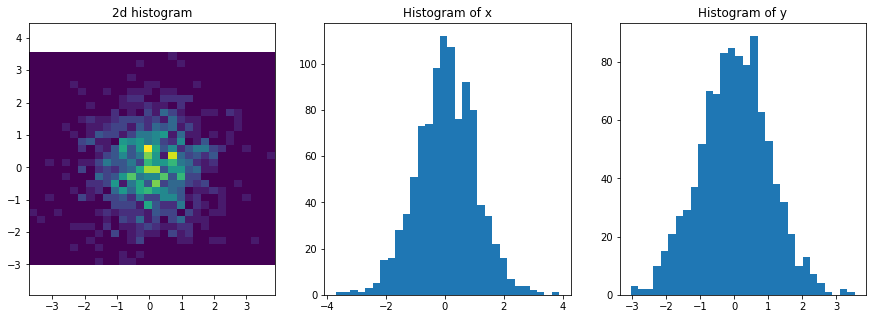

In [ ]:
%matplotlib inline

n = 1000
u1, u2 = np.random.rand(2, n)
r = np.sqrt(-2 * np.log(u1))
theta = 2 * np.pi * u2
x = r * np.cos(theta)
y = r * np.sin(theta)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor('xkcd:white')
ax[0].hist2d(x, y, bins=30)
ax[0].axis('equal')
ax[1].hist(x, bins=30)
ax[2].hist(y, bins=30)
ax[0].set_title("2d histogram")
ax[1].set_title("Histogram of x")
ax[2].set_title("Histogram of y")
plt.show()

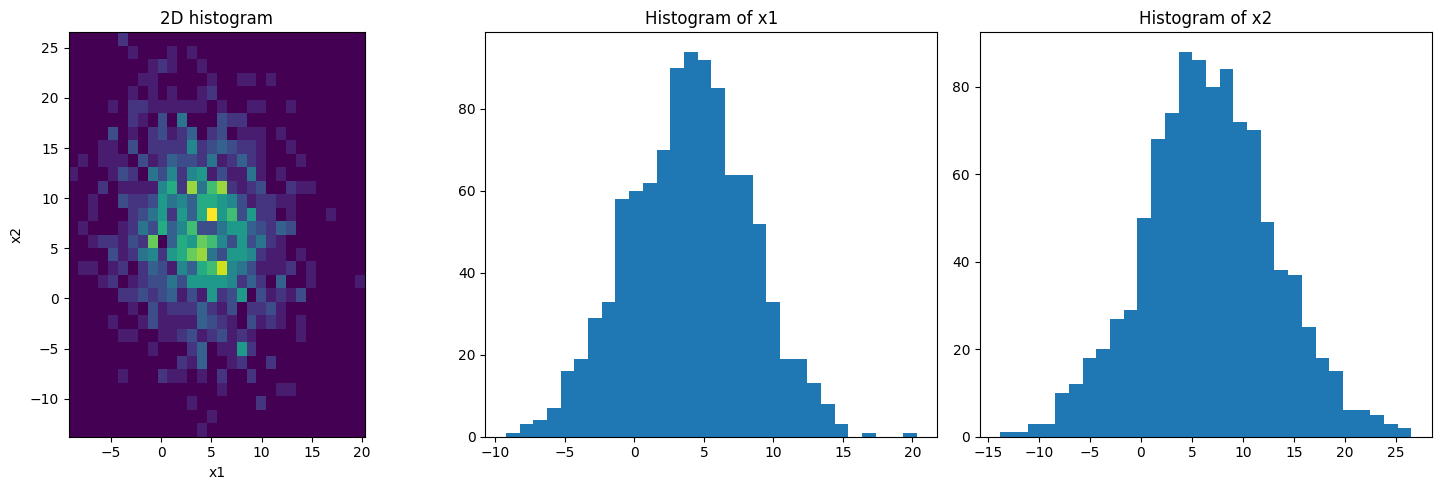

Выборочное среднее: [3.9579274  6.67878142]
Точное среднее:     [4. 7.]

Выборочная ковариация:
 [[18.94468164 -4.90054005]
 [-4.90054005 41.17587421]]
Точная ковариация:
 [[20. -4.]
 [-4. 40.]]


In [39]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline


def box_muller_polar(n, rng=None):
    rng = rng or np.random.default_rng()
    out = np.empty((n, 2))
    filled = 0
    while filled < n:
        batch = n - filled
        v1 = rng.uniform(-1, 1, size=batch)
        v2 = rng.uniform(-1, 1, size=batch)
        s = v1**2 + v2**2
        mask = (s < 1) & (s > 0)
        f = np.sqrt(-2 * np.log(s[mask]) / s[mask])
        out[filled:filled + mask.sum()] = np.column_stack([f * v1[mask],
                                                           f * v2[mask]])
        filled += mask.sum()
    return out


mu = np.array([4.0, 7.0])
Sigma = np.array([[20.0, -4.0],
                  [-4.0, 40.0]])

N = 1000
rng = np.random.default_rng(0)

Z = box_muller_polar(N, rng)
L = np.linalg.cholesky(Sigma)
X = Z @ L.T + mu


fig, ax = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor('xkcd:white')

ax[0].hist2d(X[:, 0], X[:, 1], bins=30)
ax[0].set_title("2D histogram")
ax[0].set_xlabel("x1"); ax[0].set_ylabel("x2")
ax[0].set_aspect('equal', adjustable='box')

ax[1].hist(X[:, 0], bins=30)
ax[1].set_title("Histogram of x1")

ax[2].hist(X[:, 1], bins=30)
ax[2].set_title("Histogram of x2")

plt.tight_layout()
plt.show()

print("Выборочное среднее:", X.mean(axis=0))
print("Точное среднее:    ", mu)
print()
print("Выборочная ковариация:\n", np.cov(X, rowvar=False))
print("Точная ковариация:\n", Sigma)

### Задача 10*

Реализовать метод генерации случайного разбиения n-элементного множества на подмножества. С его помощью оценить ожидаемое число подмножеств в случайном разбиении множества из 100 элементов.

Подсказка 1: Ширяев, Вероятность, т1, задача 2 к параграфу 1.

Подсказка 2: http://djalil.chafai.net/blog/2012/05/03/generating-uniform-random-partitions/

In [41]:
import numpy as np
from scipy.special import stirling2  # числа Стирлинга 2-го рода S(n,k)

def random_set_partition(n, rng=None):
    rng = rng or np.random.default_rng()

    ks = np.arange(1, n + 1)
    stir = stirling2(n, ks).astype(float)
    probs = stir / stir.sum()
    k = rng.choice(ks, p=probs)
    labels = rng.integers(0, k, size=n)

    if n >= k:
        labels[:k] = np.arange(k)
    rng.shuffle(labels)


    blocks = [set(np.where(labels == b)[0]) for b in range(k)]
    return blocks


n = 100
N = 10000
rng = np.random.default_rng(0)
counts = []
for _ in range(N):
    blocks = random_set_partition(n, rng)
    counts.append(len(blocks))

print("оценка для n=100:", np.mean(counts))
print("Выборочное стандартное отклонение:", np.std(counts, ddof=1))

оценка для n=100: 28.5956
Выборочное стандартное отклонение: 2.4132639773349354
